# Import a Biacore Cycle/sample text export

Import **`biacore_cycle_sample.tsv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it does not download data or fit a model.

**Data origin:** [Duke TitrationAnalysis T200 example](https://github.com/DukeCHSI/TitrationAnalysis/blob/cb8112503658d24c4c6576503243fa506bf99e27/Example%20Files%20-%20T200/Example%20T200%20Chip%201%20Channel%202.txt). TitrationAnalysis tool, Kan Li and S Moses Dennison, Duke University. [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/TitrationAnalysis-LICENSE).

In [1]:
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

%matplotlib inline

# Works from the repository root, notebooks/, or docs/notebooks/.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, *cwd.parents)
    if (path / "src" / "pykingenie").is_dir()
    and (path / "test_files" / "spr_exports").is_dir()
)
sys.path.insert(0, str(repo_root / "src"))
from pykingenie import detect_file_format, SprTextExperiment, KineticsAnalyzer, plot_plate_info

plt.rcParams.update({"figure.dpi": 110, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
data_file = repo_root / "notebooks" / "data" / "spr_exports" / "biacore_cycle_sample.tsv"
print("Input:", data_file.name)

Input: biacore_cycle_sample.tsv


## File layout and representative selection

Tab-separated pairs for cycles 20, 21, and 22 of the same AE.A244 series, selected to show clear responses. The verbatim labels are `50 µg`, `100 µ`, and `200 µ`. The original Windows-1252 text is converted to UTF-8; all finite time/response pairs are retained at their recorded sampling resolution.

These mass/truncated concentration labels do not establish molar units, and the reader leaves concentrations `NaN`. The source has eight incomplete or non-finite pairs in cycle 21. Only those eight pairs are omitted from this teaching export. There is no interpolation, smoothing or response correction.

These exports do not establish injection-event timing. The boundaries below
remain **illustrative API partitions**, not verified experimental events.
The sensorgram plot rejoins all partitions on the original time grid.
Verify actual injection timing and concentrations before fitting. Boundaries
are seconds, and association is `[association_start, association_end)`.

The expected missing-concentration warning is displayed below.
`sample_id="unassigned"` is a grouping placeholder, not a recovered sample identity.

In [2]:
association_start = 0.0   # illustrative; replace with actual timing
association_end = 300.0  # illustrative; replace with actual timing

print("Detected layout:", detect_file_format(data_file))

experiment = SprTextExperiment("biacore_cycle_sample")
with warnings.catch_warnings(record=True) as messages:
    warnings.simplefilter("always", UserWarning)
    experiment.read_file(
        data_file,
        association_start=association_start,
        association_end=association_end,
        decimal='.',
        time_unit="s",
        sample_id="unassigned",
    )
for message in messages:
    print(message.message)
print(f"Imported {experiment.no_sensors} measured curves; {experiment.no_steps} API phases.")
assert experiment.traces_loaded and experiment.no_sensors == 3

Detected layout: spr_text
Some analyte concentrations are unavailable or have no unit. Provide concentrations or edit ligand_conc_df before fitting.
Imported 3 measured curves; 3 API phases.


## Available curve information

Each measured curve becomes a sensor in the experiment object. Its complete
original label remains in `sensor_names`. The following table extracts only
the header/row-label fields present in this specific example file.

In [3]:
curve_ids = [f"Curve {i + 1}" for i in range(experiment.no_sensors)]
labels = pd.Series(experiment.sensor_names, name="Exported label")
header_info = labels.str.extract('Cycle:\\s*(?P<Cycle>\\d+)\\s+(?P<Sample_label>\\S+)\\s+(?P<Concentration_label>.+)$')
header_info.insert(0, "Curve", curve_ids)
display(header_info)
display(labels.to_frame())
plot_labels = header_info["Concentration_label"].tolist()

,Curve,Cycle,Sample_label,Concentration_label
0,Curve 1,20,AE.A244,50 µg
1,Curve 2,21,AE.A244,100 µ
2,Curve 3,22,AE.A244,200 µ


,Exported label
0,Cycle: 20 AE.A244 50 µg
1,Cycle: 21 AE.A244 100 µ
2,Cycle: 22 AE.A244 200 µ


## Concentration metadata

`NaN` means a molar concentration is unavailable, not zero concentration.
Before fitting, supply your verified values through `concentrations` and
`concentration_unit` at import, or update `ligand_conc_df`. A list follows the
measured-curve order; a mapping can use full exported curve labels as keys.

In [4]:
concentration_info = experiment.ligand_conc_df.copy()
concentration_info.insert(0, "Curve", curve_ids)
display(concentration_info[["Curve", "Concentration_micromolar", "SampleID"]])
assert concentration_info["Concentration_micromolar"].isna().all()

,Curve,Concentration_micromolar,SampleID
0,Curve 1,NaN,unassigned
1,Curve 2,NaN,unassigned
2,Curve 3,NaN,unassigned


## Plate information, when available

Cycle numbers and the `AE.A244` sample label do not establish plate coordinates. No plate layout is present in this text export.

The conditional cell below uses `plot_plate_info` only when the experiment
actually contains the required plate metadata. It prints a message for this
file rather than assigning artificial well positions.

In [5]:
analyzer = KineticsAnalyzer()
analyzer.add_experiment(experiment, experiment.name)
plate_fields = (
    "sample_row", "sample_column", "sample_type", "sample_id", "sample_conc_labeled"
)
have_plate_info = all(
    getattr(experiment, field) is not None
    and len(getattr(experiment, field)) > 0
    for field in plate_fields
)
if have_plate_info:
    display(pd.DataFrame({field: getattr(experiment, field) for field in plate_fields}))
    plot_plate_info(analyzer, experiment.name).show()
else:
    print("No plate-well coordinates are available in this export; no plate plot is created.")

No plate-well coordinates are available in this export; no plate plot is created.


## Imported sensorgrams

Every finite source observation in the selected curves is plotted at its original
time. No resampling, smoothing or baseline subtraction is applied. Lines break
across gaps larger than three median sampling intervals. Legend entries use the
original concentration labels or cycle/flow-cell identifiers shown above.

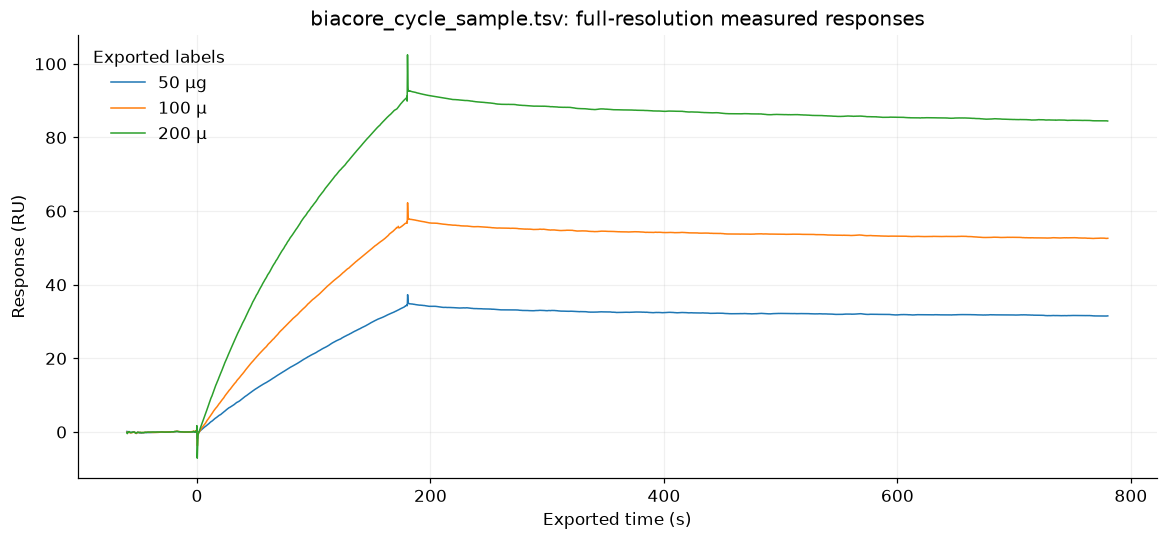

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.8), constrained_layout=True)
axes = [ax]
for i, label in enumerate(plot_labels):
    time = np.concatenate(experiment.xs[i])
    response = np.concatenate(experiment.ys[i])
    breaks = np.flatnonzero(np.diff(time) > 3 * np.median(np.diff(time))) + 1
    segments = np.split(np.arange(len(time)), breaks)
    for axis in axes:
        for j, indices in enumerate(segments):
            axis.plot(time[indices], response[indices], color=f"C{i}", linewidth=1,
                      label=label if j == 0 else None)
for axis in axes:
    axis.set(xlabel="Exported time (s)", ylabel="Response (RU)")
    axis.legend(frameon=False, title="Exported labels")
    axis.grid(alpha=0.18)
ax.set_title("biacore_cycle_sample.tsv: full-resolution measured responses")
plt.show()

## Check the retained points and API partitions

The original times remain in `xs`; `ys` contains the corresponding measured
responses. The phase counts below reflect the illustrative boundaries above,
not injection events detected from the signal.

In [7]:
imported_points = pd.DataFrame([
    {
        "Curve": curve_ids[i],
        "Baseline points": len(experiment.xs[i][0]),
        "Association points": len(experiment.xs[i][1]),
        "Dissociation points": len(experiment.xs[i][2]),
        "Total points": sum(len(step) for step in experiment.xs[i]),
        "First exported time (s)": np.concatenate(experiment.xs[i])[0],
        "Last exported time (s)": np.concatenate(experiment.xs[i])[-1],
    }
    for i in range(experiment.no_sensors)
])
display(imported_points)
display(experiment.df_steps[["Name", "Type", "Start"]])

,Curve,Baseline points,Association points,Dissociation points,Total points,First exported time (s),Last exported time (s)
0,Curve 1,601,3000,4803,8404,-60.06,780.24
1,Curve 2,600,2992,4803,8395,-59.96,780.24
2,Curve 3,600,3000,4802,8402,-59.96,780.14


,Name,Type,Start
0,Baseline,BASELINE,-60.06
1,Association,ASSOC,0.00
2,Dissociation,DISASSOC,300.00


These teaching exports contain complete source sampling for the selected
curves, excluding only the explicitly documented missing pairs. Their original
offsets and independent time grids are preserved. The small files used for parser
regression tests remain separate in `test_files/spr_exports/`.

Selection details, missing-pair counts, provenance and licenses:
[SOURCES.md](data/spr_exports/SOURCES.md).